In [1]:
!pip install -q kagglehub timm seaborn scikit-learn

In [2]:
import os
import random
import json
import copy
import time

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


In [4]:
PROJECT_NAME = "EcoSort-AI"

CONFIG = {
    "dataset": "Garbage Classification",
    "num_classes": 12,
    "image_size": 224,
    "batch_size": 32,
    "epochs": 15,
    "learning_rate": 0.001,
    "seed": SEED,
    "architecture": "EfficientNet-B0"
}

for key, value in CONFIG.items():
    print(f"{key}: {value}")

dataset: Garbage Classification
num_classes: 12
image_size: 224
batch_size: 32
epochs: 15
learning_rate: 0.001
seed: 42
architecture: EfficientNet-B0


In [5]:
import kagglehub

DATASET_PATH = Path(
    kagglehub.dataset_download(
        "mostafaabla/garbage-classification"
    )
)

print("Dataset downloaded to:", DATASET_PATH)

Using Colab cache for faster access to the 'garbage-classification' dataset.
Dataset downloaded to: /kaggle/input/garbage-classification


In [6]:
for root, dirs, files in os.walk(DATASET_PATH):

    level = root.replace(str(DATASET_PATH), "").count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    indent = " " * 4 * level

    print(f"{indent}{Path(root).name}/")

    if level >= 2:
        continue

    for file in files[:5]:
        print(f"{indent}    {file}")

garbage-classification/
    garbage_classification/
        metal/
        white-glass/
        biological/
        paper/
        brown-glass/
        battery/
        trash/
        cardboard/
        shoes/
        clothes/
        plastic/
        green-glass/


In [7]:
# Find the directory containing all class folders

CLASS_NAMES = [
    "battery",
    "biological",
    "brown-glass",
    "cardboard",
    "clothes",
    "green-glass",
    "metal",
    "paper",
    "plastic",
    "shoes",
    "trash",
    "white-glass"
]

DATA_ROOT = None

for root, dirs, files in os.walk(DATASET_PATH):
    if all(class_name in dirs for class_name in CLASS_NAMES):
        DATA_ROOT = Path(root)
        break

if DATA_ROOT is None:
    raise FileNotFoundError("12 class folders were not found!")

print("Dataset root:", DATA_ROOT)

Dataset root: /kaggle/input/garbage-classification/garbage_classification


In [8]:
image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

class_counts = {}

for class_name in CLASS_NAMES:
    class_dir = DATA_ROOT / class_name

    images = [
        file for file in class_dir.iterdir()
        if file.suffix.lower() in image_extensions
    ]

    class_counts[class_name] = len(images)

class_df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Image Count"]
)

display(class_df)

print("Total classes:", len(class_counts))
print("Total images:", sum(class_counts.values()))

,Class,Image Count
0,battery,945
1,biological,985
2,brown-glass,607
3,cardboard,891
4,clothes,5325
5,green-glass,629
6,metal,769
7,paper,1050
8,plastic,865
9,shoes,1977


Total classes: 12
Total images: 15515


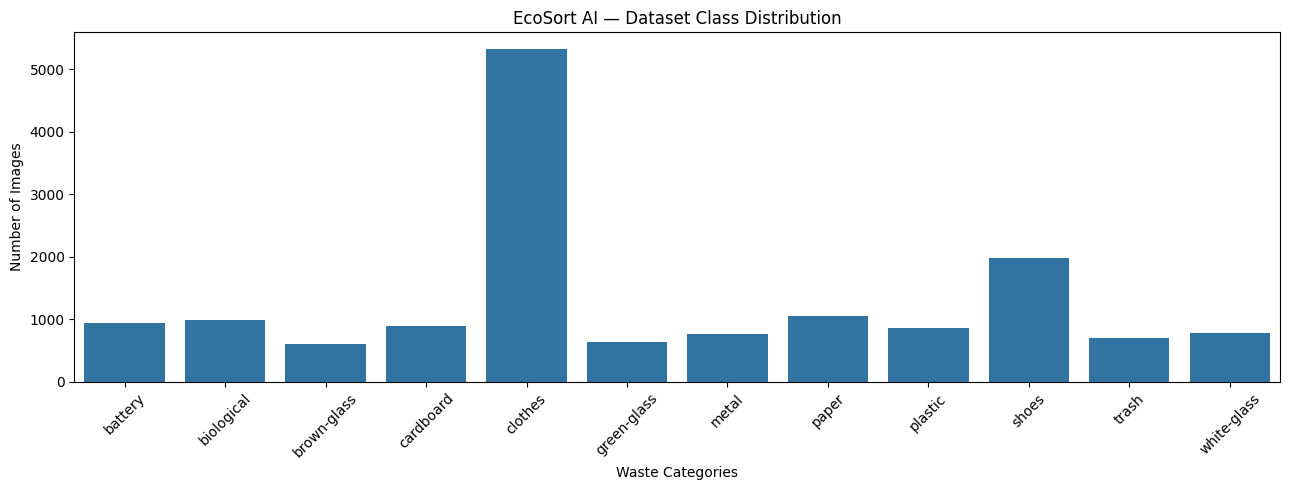

In [9]:
plt.figure(figsize=(13, 5))

sns.barplot(
    data=class_df,
    x="Class",
    y="Image Count"
)

plt.title("EcoSort AI — Dataset Class Distribution")
plt.xlabel("Waste Categories")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
from PIL import Image

image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

class_to_idx = {
    class_name: idx
    for idx, class_name in enumerate(CLASS_NAMES)
}

image_paths = []
image_labels = []
corrupted_images = []

for class_name in CLASS_NAMES:
    class_dir = DATA_ROOT / class_name

    for image_path in class_dir.iterdir():
        if image_path.suffix.lower() not in image_extensions:
            continue

        try:
            with Image.open(image_path) as img:
                img.verify()

            image_paths.append(str(image_path))
            image_labels.append(class_to_idx[class_name])

        except Exception:
            corrupted_images.append(str(image_path))

print("Valid images:", len(image_paths))
print("Corrupted images:", len(corrupted_images))
print("Number of classes:", len(class_to_idx))

Valid images: 15515
Corrupted images: 0
Number of classes: 12


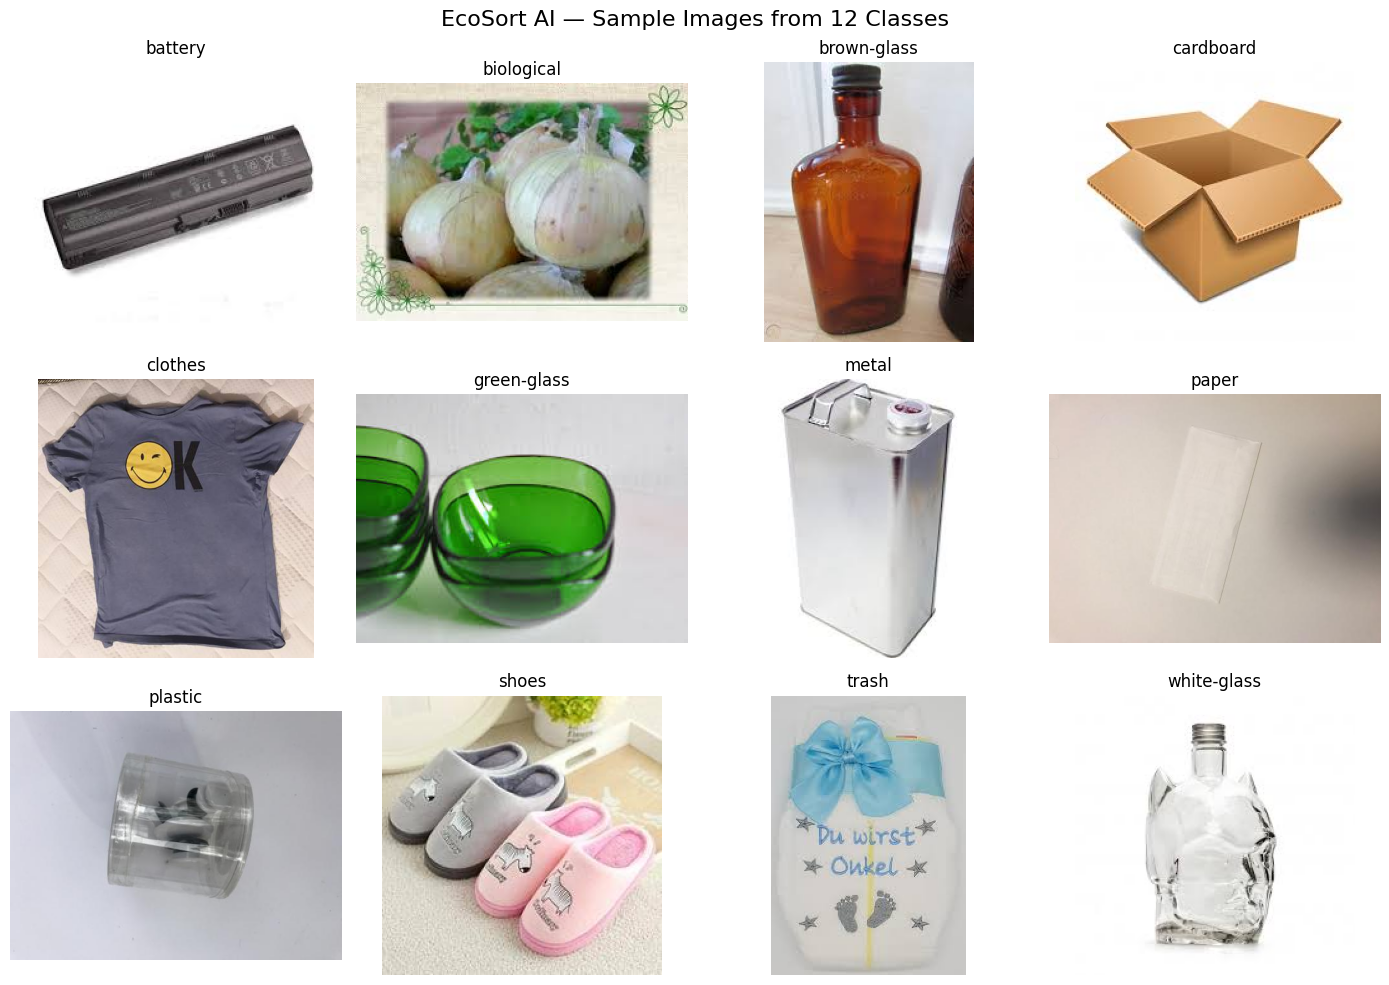

In [11]:
fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for class_idx, ax in enumerate(axes.flat):
    class_name = CLASS_NAMES[class_idx]

    class_samples = [
        path for path, label in zip(image_paths, image_labels)
        if label == class_idx
    ]

    sample_path = random.choice(class_samples)

    img = Image.open(sample_path).convert("RGB")

    ax.imshow(img)
    ax.set_title(class_name)
    ax.axis("off")

plt.suptitle("EcoSort AI — Sample Images from 12 Classes", fontsize=16)
plt.tight_layout()
plt.show()

In [12]:
from sklearn.model_selection import train_test_split

X = np.array(image_paths)
y = np.array(image_labels)

# 80% train, 20% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

# Temporary set: 10% validation, 10% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))
print("Total:", len(X_train) + len(X_val) + len(X_test))

Train: 12412
Validation: 1551
Test: 1552
Total: 15515


In [13]:
split_df = pd.DataFrame({
    "Train": pd.Series(y_train).value_counts().sort_index(),
    "Validation": pd.Series(y_val).value_counts().sort_index(),
    "Test": pd.Series(y_test).value_counts().sort_index()
})

split_df.index = CLASS_NAMES

display(split_df)

,Train,Validation,Test
battery,756,94,95
biological,788,98,99
brown-glass,485,61,61
cardboard,713,89,89
clothes,4260,532,533
green-glass,503,63,63
metal,615,77,77
paper,840,105,105
plastic,692,87,86
shoes,1582,197,198


In [14]:
# ImageNet normalization
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

In [15]:
class WasteDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image_path = self.image_paths[idx]
        label = int(self.labels[idx])

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label


train_dataset = WasteDataset(
    X_train, y_train, train_transform
)

val_dataset = WasteDataset(
    X_val, y_val, eval_transform
)

test_dataset = WasteDataset(
    X_test, y_test, eval_transform
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 12412
Validation dataset: 1551
Test dataset: 1552


In [16]:
BATCH_SIZE = CONFIG["batch_size"]

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 388
Validation batches: 49
Test batches: 49


In [17]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Labels shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)
print("Device:", DEVICE)

Image batch shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Image dtype: torch.float32
Label dtype: torch.int64
Device: cuda


In [18]:
# Load pretrained EfficientNet-B0
weights = models.EfficientNet_B0_Weights.DEFAULT

model = models.efficientnet_b0(weights=weights)

# Freeze feature extractor initially
for param in model.features.parameters():
    param.requires_grad = False

# Replace final classification layer
in_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    in_features,
    CONFIG["num_classes"]
)

model = model.to(DEVICE)

print(model.classifier)
print("\nModel device:", next(model.parameters()).device)
print("Output classes:", CONFIG["num_classes"])

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 76.9MB/s]


Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=12, bias=True)
)

Model device: cuda:0
Output classes: 12


In [19]:
class_counts_train = np.bincount(
    y_train,
    minlength=CONFIG["num_classes"]
)

# Moderate inverse-frequency weighting
class_weights = 1.0 / np.sqrt(class_counts_train)

# Normalize weights
class_weights = class_weights / class_weights.mean()

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(DEVICE)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

print("Class weights:")

for name, weight in zip(CLASS_NAMES, class_weights.cpu().numpy()):
    print(f"{name:15s}: {weight:.3f}")

Class weights:
battery        : 1.003
biological     : 0.982
brown-glass    : 1.252
cardboard      : 1.033
clothes        : 0.422
green-glass    : 1.229
metal          : 1.112
paper          : 0.951
plastic        : 1.048
shoes          : 0.693
trash          : 1.167
white-glass    : 1.107


In [20]:
# Training configuration
HEAD_EPOCHS = 5
FINETUNE_EPOCHS = 10

BEST_MODEL_PATH = "/content/ecosort_efficientnet_b0_best.pth"

best_val_loss = float("inf")

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

print("Stage 1 epochs:", HEAD_EPOCHS)
print("Stage 2 epochs:", FINETUNE_EPOCHS)
print("Total epochs:", HEAD_EPOCHS + FINETUNE_EPOCHS)

Stage 1 epochs: 5
Stage 2 epochs: 10
Total epochs: 15


In [21]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc


def evaluate(model, loader, criterion):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

In [22]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc


def evaluate(model, loader, criterion):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

In [23]:
def fit_model(model, train_loader, val_loader,
              criterion, optimizer, scheduler,
              epochs, stage_name):

    global best_val_loss

    print(f"\n{'='*55}")
    print(f"Starting {stage_name}")
    print(f"{'='*55}")

    for epoch in range(epochs):
        start_time = time.time()

        train_loss, train_acc = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer
        )

        val_loss, val_acc = evaluate(
            model,
            val_loader,
            criterion
        )

        if scheduler is not None:
            scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss

            torch.save({
                "model_state_dict": model.state_dict(),
                "class_names": CLASS_NAMES,
                "config": CONFIG,
                "val_loss": best_val_loss
            }, BEST_MODEL_PATH)

            status = "Saved best model"
        else:
            status = ""

        elapsed = time.time() - start_time

        print(
            f"Epoch [{epoch+1:02d}/{epochs}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"{elapsed:.1f}s | {status}"
        )

In [24]:
optimizer = optim.AdamW(
    model.classifier.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

fit_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    epochs=HEAD_EPOCHS,
    stage_name="STAGE 1 — CLASSIFIER TRAINING"
)


Starting STAGE 1 — CLASSIFIER TRAINING
Epoch [01/5] Train Loss: 0.8265 | Train Acc: 0.8236 | Val Loss: 0.4802 | Val Acc: 0.8975 | 85.2s | Saved best model
Epoch [02/5] Train Loss: 0.4618 | Train Acc: 0.8834 | Val Loss: 0.3702 | Val Acc: 0.9155 | 82.9s | Saved best model
Epoch [03/5] Train Loss: 0.3982 | Train Acc: 0.8969 | Val Loss: 0.3242 | Val Acc: 0.9220 | 84.8s | Saved best model
Epoch [04/5] Train Loss: 0.3825 | Train Acc: 0.8997 | Val Loss: 0.3121 | Val Acc: 0.9194 | 84.9s | Saved best model
Epoch [05/5] Train Loss: 0.3480 | Train Acc: 0.9065 | Val Loss: 0.2948 | Val Acc: 0.9233 | 91.9s | Saved best model


In [25]:
 # Freeze all feature layers
for param in model.features.parameters():
    param.requires_grad = False

# Unfreeze the last three feature blocks
for block in model.features[-3:]:
    for param in block.parameters():
        param.requires_grad = True

# Keep classifier trainable
for param in model.classifier.parameters():
    param.requires_grad = True

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel() for p in model.parameters()
)

print(f"Trainable parameters: {trainable_params:,}")
print(f"Total parameters: {total_params:,}")
print(f"Trainable percentage: {100*trainable_params/total_params:.2f}%")

Trainable parameters: 3,171,112
Total parameters: 4,022,920
Trainable percentage: 78.83%


In [26]:
optimizer = optim.AdamW(
    [
        {
            "params": model.features[-3:].parameters(),
            "lr": 1e-5
        },
        {
            "params": model.classifier.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

fit_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    epochs=FINETUNE_EPOCHS,
    stage_name="STAGE 2 — FINE-TUNING"
)


Starting STAGE 2 — FINE-TUNING
Epoch [01/10] Train Loss: 0.3095 | Train Acc: 0.9166 | Val Loss: 0.2777 | Val Acc: 0.9259 | 88.7s | Saved best model
Epoch [02/10] Train Loss: 0.2723 | Train Acc: 0.9252 | Val Loss: 0.2483 | Val Acc: 0.9355 | 85.4s | Saved best model
Epoch [03/10] Train Loss: 0.2557 | Train Acc: 0.9286 | Val Loss: 0.2215 | Val Acc: 0.9446 | 87.9s | Saved best model
Epoch [04/10] Train Loss: 0.2429 | Train Acc: 0.9335 | Val Loss: 0.2165 | Val Acc: 0.9452 | 87.1s | Saved best model
Epoch [05/10] Train Loss: 0.2155 | Train Acc: 0.9408 | Val Loss: 0.2047 | Val Acc: 0.9426 | 86.5s | Saved best model
Epoch [06/10] Train Loss: 0.2027 | Train Acc: 0.9435 | Val Loss: 0.2097 | Val Acc: 0.9478 | 85.3s | 
Epoch [07/10] Train Loss: 0.1905 | Train Acc: 0.9452 | Val Loss: 0.1861 | Val Acc: 0.9516 | 87.9s | Saved best model
Epoch [08/10] Train Loss: 0.1783 | Train Acc: 0.9503 | Val Loss: 0.1857 | Val Acc: 0.9516 | 89.7s | Saved best model
Epoch [09/10] Train Loss: 0.1731 | Train Acc: 0.

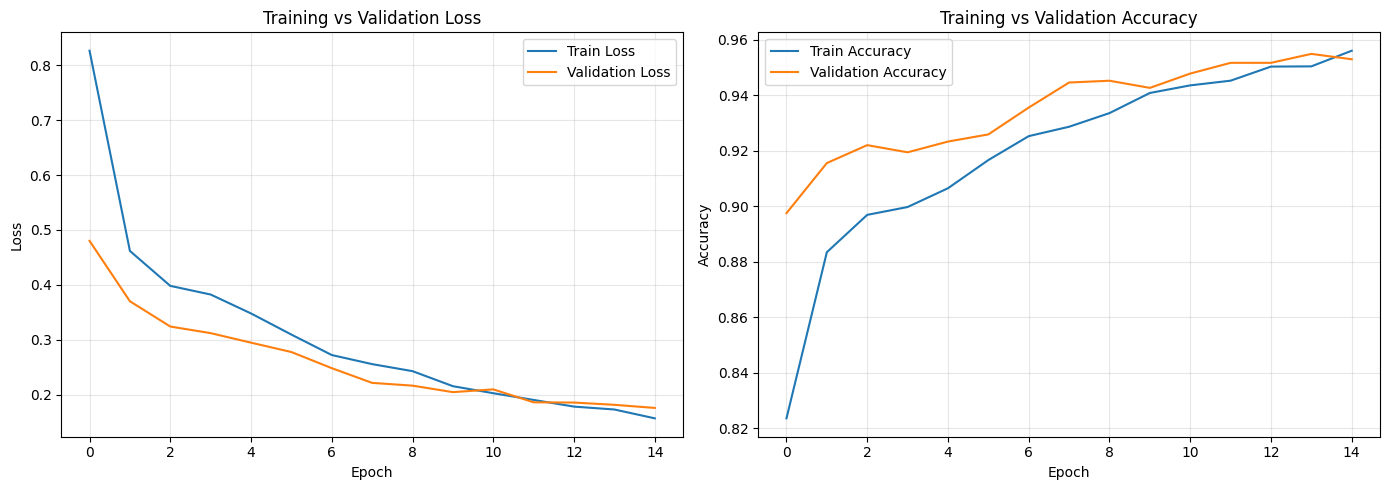

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history["train_loss"], label="Train Loss")
axes[0].plot(history["val_loss"], label="Validation Loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history["train_acc"], label="Train Accuracy")
axes[1].plot(history["val_acc"], label="Validation Accuracy")
axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [28]:
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best checkpoint loaded!")
print("Best validation loss:", checkpoint["val_loss"])

Best checkpoint loaded!
Best validation loss: 0.1759389821730607


In [29]:
all_predictions = []
all_labels = []
all_probabilities = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)
all_probabilities = np.array(all_probabilities)

test_accuracy = accuracy_score(all_labels, all_predictions)
test_f1_macro = f1_score(
    all_labels, all_predictions, average="macro"
)
test_f1_weighted = f1_score(
    all_labels, all_predictions, average="weighted"
)

print(f"Test Accuracy:    {test_accuracy:.4f}")
print(f"Macro F1-score:   {test_f1_macro:.4f}")
print(f"Weighted F1:      {test_f1_weighted:.4f}")

Test Accuracy:    0.9478
Macro F1-score:   0.9308
Weighted F1:      0.9478


In [30]:
report = classification_report(
    all_labels,
    all_predictions,
    target_names=CLASS_NAMES,
    digits=4
)

print(report)

              precision    recall  f1-score   support

     battery     0.8942    0.9789    0.9347        95
  biological     0.9515    0.9899    0.9703        99
 brown-glass     0.9206    0.9508    0.9355        61
   cardboard     0.9341    0.9551    0.9444        89
     clothes     0.9981    0.9719    0.9848       533
 green-glass     0.9394    0.9841    0.9612        63
       metal     0.8222    0.9610    0.8862        77
       paper     0.9570    0.8476    0.8990       105
     plastic     0.8642    0.8140    0.8383        86
       shoes     0.9548    0.9596    0.9572       198
       trash     0.9710    0.9710    0.9710        69
 white-glass     0.9054    0.8701    0.8874        77

    accuracy                         0.9478      1552
   macro avg     0.9260    0.9378    0.9308      1552
weighted avg     0.9494    0.9478    0.9478      1552



In [32]:
class_accuracy = cm.diagonal() / cm.sum(axis=1)

class_results = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Test Images": cm.sum(axis=1),
    "Correct Predictions": cm.diagonal(),
    "Accuracy": class_accuracy
})

class_results["Accuracy"] = (
    class_results["Accuracy"] * 100
).round(2)

display(
    class_results.sort_values(
        "Accuracy",
        ascending=False
    )
)

,Class,Test Images,Correct Predictions,Accuracy
1,biological,99,98,98.99
5,green-glass,63,62,98.41
0,battery,95,93,97.89
4,clothes,533,518,97.19
10,trash,69,67,97.10
6,metal,77,74,96.10
9,shoes,198,190,95.96
3,cardboard,89,85,95.51
2,brown-glass,61,58,95.08
11,white-glass,77,67,87.01


In [33]:
def predict_image(image_path):
    image = Image.open(image_path).convert("RGB")

    input_tensor = eval_transform(image).unsqueeze(0).to(DEVICE)

    model.eval()

    with torch.no_grad():
        output = model(input_tensor)
        probabilities = torch.softmax(output, dim=1)

    confidence, predicted_idx = probabilities.max(dim=1)

    predicted_class = CLASS_NAMES[predicted_idx.item()]
    confidence = confidence.item() * 100

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Confidence: {confidence:.2f}%"
    )
    plt.show()

    return predicted_class, confidence

Saving shoes.jpg to shoes.jpg


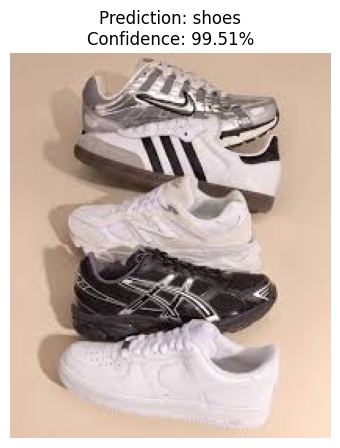

Image: shoes.jpg
Predicted class: shoes
Confidence: 99.51%
----------------------------------------


In [44]:
from google.colab import files

uploaded = files.upload()

for filename in uploaded.keys():
    predicted_class, confidence = predict_image(filename)

    print("Image:", filename)
    print("Predicted class:", predicted_class)
    print(f"Confidence: {confidence:.2f}%")
    print("-" * 40)

In [45]:
import torch.nn.functional as F

def generate_gradcam(model, image_path):
    model.eval()

    target_layer = model.features[-1]

    activations = []
    gradients = []

    def forward_hook(module, input, output):
        activations.append(output)

    def backward_hook(module, grad_input, grad_output):
        gradients.append(grad_output[0])

    forward_handle = target_layer.register_forward_hook(forward_hook)
    backward_handle = target_layer.register_full_backward_hook(backward_hook)

    image = Image.open(image_path).convert("RGB")
    input_tensor = eval_transform(image).unsqueeze(0).to(DEVICE)

    model.zero_grad()

    output = model(input_tensor)
    predicted_idx = output.argmax(dim=1).item()
    confidence = torch.softmax(output, dim=1)[0, predicted_idx].item()

    output[0, predicted_idx].backward()

    acts = activations[0]
    grads = gradients[0]

    weights = grads.mean(dim=(2, 3), keepdim=True)

    cam = (weights * acts).sum(dim=1, keepdim=True)
    cam = F.relu(cam)

    cam = F.interpolate(
        cam,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )

    cam = cam.squeeze().detach().cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    forward_handle.remove()
    backward_handle.remove()

    original = np.array(image.resize((224, 224)))

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(original)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(original)
    plt.imshow(cam, cmap="jet", alpha=0.45)
    plt.title(
        f"Grad-CAM: {CLASS_NAMES[predicted_idx]}\n"
        f"Confidence: {confidence*100:.2f}%"
    )
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    return CLASS_NAMES[predicted_idx], confidence

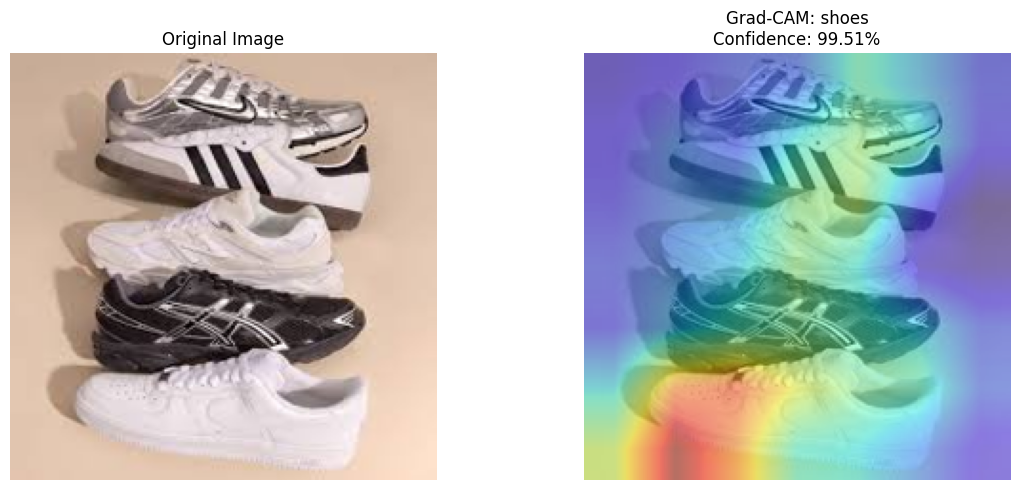

('shoes', 0.9950703382492065)

In [46]:
generate_gradcam(model, "shoes.jpg")

In [47]:
# Load pretrained ResNet50
resnet = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

# Freeze backbone
for param in resnet.parameters():
    param.requires_grad = False

# Replace final layer
in_features = resnet.fc.in_features
resnet.fc = nn.Linear(in_features, CONFIG["num_classes"])

resnet = resnet.to(DEVICE)

print("ResNet50 loaded successfully!")
print("Output classes:", CONFIG["num_classes"])

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 133MB/s]


ResNet50 loaded successfully!
Output classes: 12


In [48]:
resnet_best_path = "/content/ecosort_resnet50_best.pth"
resnet_best_loss = float("inf")

resnet_optimizer = optim.AdamW(
    resnet.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

resnet_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    resnet_optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

for epoch in range(5):
    train_loss, train_acc = train_one_epoch(
        resnet, train_loader, criterion, resnet_optimizer
    )

    val_loss, val_acc = evaluate(
        resnet, val_loader, criterion
    )

    resnet_scheduler.step(val_loss)

    if val_loss < resnet_best_loss:
        resnet_best_loss = val_loss
        torch.save(resnet.state_dict(), resnet_best_path)

    print(
        f"Epoch {epoch+1}/5 | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

Epoch 1/5 | Train Acc: 0.8603 | Val Acc: 0.9020 | Val Loss: 0.3925
Epoch 2/5 | Train Acc: 0.9316 | Val Acc: 0.9271 | Val Loss: 0.2743
Epoch 3/5 | Train Acc: 0.9416 | Val Acc: 0.9304 | Val Loss: 0.2489
Epoch 4/5 | Train Acc: 0.9469 | Val Acc: 0.9465 | Val Loss: 0.2081
Epoch 5/5 | Train Acc: 0.9540 | Val Acc: 0.9381 | Val Loss: 0.2111


In [49]:
# Unfreeze layer4
for param in resnet.layer4.parameters():
    param.requires_grad = True

resnet_optimizer = optim.AdamW(
    [
        {"params": resnet.layer4.parameters(), "lr": 1e-5},
        {"params": resnet.fc.parameters(), "lr": 1e-4}
    ],
    weight_decay=1e-4
)

resnet_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    resnet_optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

for epoch in range(10):
    train_loss, train_acc = train_one_epoch(
        resnet, train_loader, criterion, resnet_optimizer
    )

    val_loss, val_acc = evaluate(
        resnet, val_loader, criterion
    )

    resnet_scheduler.step(val_loss)

    if val_loss < resnet_best_loss:
        resnet_best_loss = val_loss
        torch.save(resnet.state_dict(), resnet_best_path)

    print(
        f"Fine-tune {epoch+1}/10 | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

Fine-tune 1/10 | Train Acc: 0.9590 | Val Acc: 0.9446 | Val Loss: 0.1816
Fine-tune 2/10 | Train Acc: 0.9689 | Val Acc: 0.9491 | Val Loss: 0.1667
Fine-tune 3/10 | Train Acc: 0.9705 | Val Acc: 0.9536 | Val Loss: 0.1572
Fine-tune 4/10 | Train Acc: 0.9749 | Val Acc: 0.9574 | Val Loss: 0.1525
Fine-tune 5/10 | Train Acc: 0.9799 | Val Acc: 0.9581 | Val Loss: 0.1452
Fine-tune 6/10 | Train Acc: 0.9816 | Val Acc: 0.9549 | Val Loss: 0.1466
Fine-tune 7/10 | Train Acc: 0.9865 | Val Acc: 0.9587 | Val Loss: 0.1335
Fine-tune 8/10 | Train Acc: 0.9869 | Val Acc: 0.9600 | Val Loss: 0.1369
Fine-tune 9/10 | Train Acc: 0.9874 | Val Acc: 0.9658 | Val Loss: 0.1277
Fine-tune 10/10 | Train Acc: 0.9889 | Val Acc: 0.9665 | Val Loss: 0.1248


In [50]:
def get_test_predictions(model, loader):
    model.eval()

    predictions = []
    targets = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE)

            outputs = model(images)
            preds = outputs.argmax(dim=1)

            predictions.extend(preds.cpu().numpy())
            targets.extend(labels.numpy())

    return np.array(targets), np.array(predictions)


# EfficientNet-B0
efficientnet.load_state_dict(
    torch.load(BEST_MODEL_PATH, map_location=DEVICE,
               weights_only=False)["model_state_dict"]
) if "efficientnet" in globals() else None

In [51]:
# Restore best EfficientNet-B0
model.load_state_dict(
    torch.load(
        BEST_MODEL_PATH,
        map_location=DEVICE,
        weights_only=False
    )["model_state_dict"]
)

y_true, eff_preds = get_test_predictions(model, test_loader)

# Restore best ResNet50
resnet.load_state_dict(
    torch.load(resnet_best_path, map_location=DEVICE)
)

_, resnet_preds = get_test_predictions(resnet, test_loader)


comparison = pd.DataFrame([
    {
        "Model": "EfficientNet-B0",
        "Accuracy": accuracy_score(y_true, eff_preds),
        "Macro F1": f1_score(y_true, eff_preds, average="macro"),
        "Weighted F1": f1_score(y_true, eff_preds, average="weighted")
    },
    {
        "Model": "ResNet50",
        "Accuracy": accuracy_score(y_true, resnet_preds),
        "Macro F1": f1_score(y_true, resnet_preds, average="macro"),
        "Weighted F1": f1_score(y_true, resnet_preds, average="weighted")
    }
])

display(comparison.round(4))

,Model,Accuracy,Macro F1,Weighted F1
0,EfficientNet-B0,0.9478,0.9308,0.9478
1,ResNet50,0.9652,0.9525,0.9651


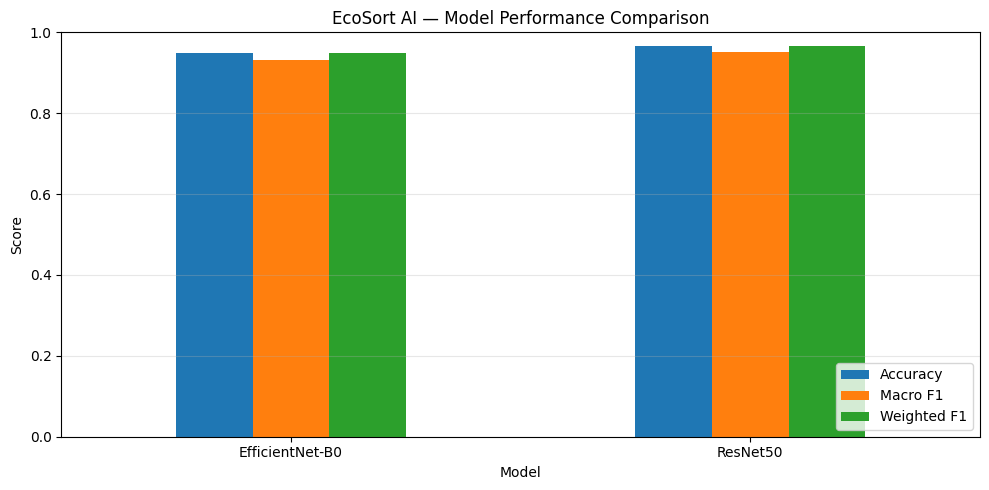

In [52]:
comparison_plot = comparison.set_index("Model")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("EcoSort AI — Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [55]:
# Restore best EfficientNet model
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Save model weights
torch.save(
    model.state_dict(),
    "/content/ecosort_efficientnet_b0.pth"
)

# Save class names
with open("/content/class_names.json", "w") as f:
    json.dump(CLASS_NAMES, f, indent=4)

print("Model exported successfully!")

Model exported successfully!


In [56]:
!pip install -q streamlit

In [57]:
%%writefile /content/app.py

import streamlit as st
import torch
import torch.nn as nn
import json

from PIL import Image
from torchvision import models, transforms


# -----------------------------
# Configuration
# -----------------------------

st.set_page_config(
    page_title="EcoSort AI",
    page_icon="♻️",
    layout="wide"
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_PATH = "ecosort_efficientnet_b0.pth"
CLASS_PATH = "class_names.json"


# -----------------------------
# Load model
# -----------------------------

@st.cache_resource
def load_model():

    with open(CLASS_PATH, "r") as f:
        class_names = json.load(f)

    model = models.efficientnet_b0(weights=None)

    in_features = model.classifier[1].in_features

    model.classifier[1] = nn.Linear(
        in_features,
        len(class_names)
    )

    state_dict = torch.load(
        MODEL_PATH,
        map_location=DEVICE,
        weights_only=True
    )

    model.load_state_dict(state_dict)
    model.to(DEVICE)
    model.eval()

    return model, class_names


model, CLASS_NAMES = load_model()


# -----------------------------
# Image preprocessing
# -----------------------------

transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])


# -----------------------------
# Prediction
# -----------------------------

def predict(image):

    image = image.convert("RGB")

    tensor = transform(image)
    tensor = tensor.unsqueeze(0).to(DEVICE)

    with torch.no_grad():

        outputs = model(tensor)

        probabilities = torch.softmax(
            outputs, dim=1
        )[0]

    top_probs, top_indices = torch.topk(
        probabilities, k=3
    )

    results = []

    for probability, index in zip(
        top_probs, top_indices
    ):
        results.append({
            "class": CLASS_NAMES[index.item()],
            "confidence": probability.item() * 100
        })

    return results


# -----------------------------
# UI
# -----------------------------

st.title("EcoSort AI")
st.subheader("AI-powered Waste Classification")

st.write(
    "Upload an image to identify its waste category "
    "using a fine-tuned EfficientNet-B0 model."
)

st.divider()

uploaded_file = st.file_uploader(
    "Upload a waste image",
    type=["jpg", "jpeg", "png", "webp"]
)

if uploaded_file:

    image = Image.open(uploaded_file)

    col1, col2 = st.columns(2)

    with col1:
        st.image(
            image,
            caption="Uploaded Image",
            use_container_width=True
        )

    with col2:

        if st.button("Classify Image", type="primary"):

            with st.spinner("Analyzing image..."):

                results = predict(image)

            best = results[0]

            st.success("Classification completed!")

            st.metric(
                "Predicted Category",
                best["class"].replace("-", " ").title()
            )

            st.metric(
                "Confidence",
                f"{best['confidence']:.2f}%"
            )

            st.subheader("Top 3 Predictions")

            for result in results:

                st.write(
                    f"**{result['class'].title()}**"
                )

                st.progress(
                    min(result["confidence"] / 100, 1.0)
                )

                st.caption(
                    f"{result['confidence']:.2f}%"
                )

st.divider()

st.caption(
    "EcoSort AI | Transfer Learning with EfficientNet-B0 | "
    "12 Waste Categories"
)

Writing /content/app.py


In [58]:
%%writefile /content/requirements.txt

streamlit
torch
torchvision
Pillow

Writing /content/requirements.txt


In [59]:
import shutil
from pathlib import Path

project_dir = Path("/content/EcoSort-AI")
project_dir.mkdir(exist_ok=True)

files_to_copy = [
    "app.py",
    "requirements.txt",
    "ecosort_efficientnet_b0.pth",
    "class_names.json"
]

for filename in files_to_copy:
    shutil.copy(
        f"/content/{filename}",
        project_dir / filename
    )

print("Project files:")
for file in project_dir.iterdir():
    print(file.name, f"({file.stat().st_size / 1024**2:.2f} MB)")

Project files:
app.py (0.00 MB)
requirements.txt (0.00 MB)
ecosort_efficientnet_b0.pth (15.64 MB)
class_names.json (0.00 MB)
